# Imágenes para la memoria

## Imports

In [3]:
from pathlib import Path

import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
import matplotlib.pyplot as plt
import numpy as np
from complex_dynamics.rational_map import RationalMap
from IPython.display import display

## Configuración

In [4]:
dpi = 600
width_inches = 6
height_inches = width_inches
horizontal_pixels = dpi * width_inches
vertical_pixels = dpi * height_inches
max_iterations = 1000
tolerance = 1e-6
julia_thickness = max(1, horizontal_pixels // 2000)
save_figures = True

# Locate the repository from a kernel started in the repo or a subdirectory.
repo_root = next(
    parent
    for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "python/src/complex_dynamics").is_dir()
)
figure_dir = repo_root / "latex/figures"

In [5]:
plt.style.use("report.mplstyle")

In [6]:
def make_mesh(center=0j, radius=2.0, *, y_radius=None):
    if y_radius is None:
        y_radius = radius
    extent = (
        center.real - radius,
        center.real + radius,
        center.imag - y_radius,
        center.imag + y_radius,
    )
    mesh = dcalc.create_mesh(
        *extent, xpixels=horizontal_pixels, ypixels=vertical_pixels
    )
    return mesh, extent


def new_axes(extent):
    width = 6
    height = width * (extent[3] - extent[2]) / (extent[1] - extent[0])
    return plt.subplots(figsize=(width, height))


def add_point(ax, point, label, *, marker="o", offset=(6, 6)):
    ax.scatter(
        [np.real(point)], [np.imag(point)], c="black", marker=marker, s=25
    )
    ax.annotate(
        label,
        (np.real(point), np.imag(point)),
        xytext=offset,
        textcoords="offset points",
        fontsize=12,
    )


def add_circle(fig, ax, center, radius, *, marker="x", linestyle="--"):
    # Plot the circle center
    ax.scatter(
        center.real,
        center.imag,
        color="lightgray",
        marker=marker,
        s=40,
        zorder=6,
    )

    circle = plt.Circle(
        (center.real, center.imag),
        radius,
        color="lightgray",
        fill=False,
        linestyle=linestyle,
        linewidth=1.5,
        alpha=0.5,
    )
    fig.gca().add_patch(circle)


def finish_figure(fig, ax, filename=None):
    ax.set_axis_off()
    fig.tight_layout(pad=0)
    if save_figures and filename is not None:
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
        )
    display(fig)
    plt.close(fig)


def plot_escape(times, extent, iterations, filename=None, *, cmap="binary"):
    fig, ax = new_axes(extent)
    dplot.plot_divergence_times(
        times,
        max_iterations=iterations,
        ax=ax,
        extent=extent,
        cmap=cmap,
        interpolation="nearest",
    )
    finish_figure(fig, ax, filename)


def plot_basins(times, points, attractors, extent, filename, *, labels=()):
    fig, ax = new_axes(extent)
    dplot.plot_convergence_times(
        times,
        points,
        attractors=attractors,
        max_iterations=max_iterations,
        ax=ax,
        extent=extent,
        interpolation="nearest",
    )
    for point, label in labels:
        add_point(ax, point, label)
    finish_figure(fig, ax, filename)


def plot_boundary(points, extent, filename):
    fig, ax = new_axes(extent)
    dplot.plot_convergence_points_boundary(
        points,
        thickness=julia_thickness,
        ax=ax,
        extent=extent,
        interpolation="nearest",
    )
    finish_figure(fig, ax, filename)

# Chapter 1: Introducción

## Section 1: Transformaciones de Möebius

### $R(z) = \frac{3z - 2}{2z - 1}$

In [50]:
R = RationalMap.from_latex(r"\frac{3z - 2}{2z - 1}")
z0 = complex(0.75, 0.25)
filename = "mobius_one_fixed_point_orbit.pdf"

In [51]:
iterations = 20
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

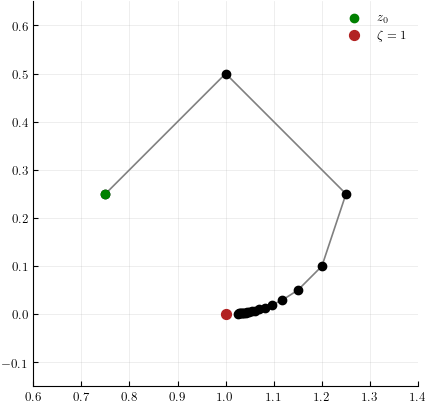

In [52]:
center = complex(
    (max(orbit.real) + min(orbit.real)) / 2,
    (max(orbit.imag) + min(orbit.imag)) / 2,
)
radius = 0.4

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
ax.scatter(1, 0, label=r"$\zeta = 1$", color="firebrick", s=50, zorder=4)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [ ]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

### $R(z) = \frac{2z}{z+1}$

In [ ]:
R = RationalMap.from_latex(r"\frac{2z}{z+1}")
z0 = complex(0.025, 0.05)
filename = "mobius_two_fixed_points_convergent_orbit.pdf"

In [83]:
iterations = 10
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

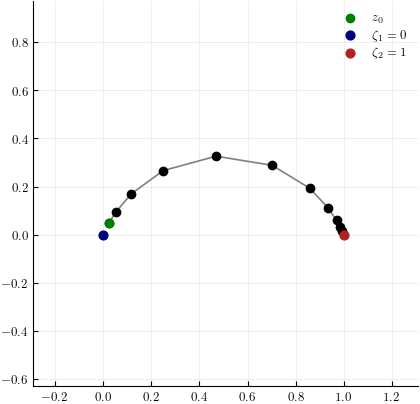

In [84]:
center = complex(
    (max(orbit.real) + min(orbit.real)) / 2,
    (max(orbit.imag) + min(orbit.imag)) / 2,
)
radius = 0.8

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
ax.scatter(0, 0, label=r"$\zeta_1 = 0$", color="navy", s=40, zorder=4)
ax.scatter(1, 0, label=r"$\zeta_2 = 1$", color="firebrick", s=40, zorder=4)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [85]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

### $R(z) = \frac{z \left(1 + i\right) + (1 - i)}{z \left(1 - i\right) + (1 + i)}$

In [136]:
a = complex(1, 1)
b = complex(1, -1)
R = RationalMap(
    np.array([b, a], dtype=np.complex128), np.array([a, b], dtype=np.complex128)
)

z0 = complex(1 / 2, 0)
filename = "mobius_two_fixed_points_periodic_orbit.pdf"

# Calculate mathematical center
C = abs((z0 - 1) / (z0 + 1))
center_x = (1 + C**2) / (1 - C**2)
center_circle = complex(center_x, 0)
radius_circle = abs(z0 - center_circle)

In [137]:
iterations = 4
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

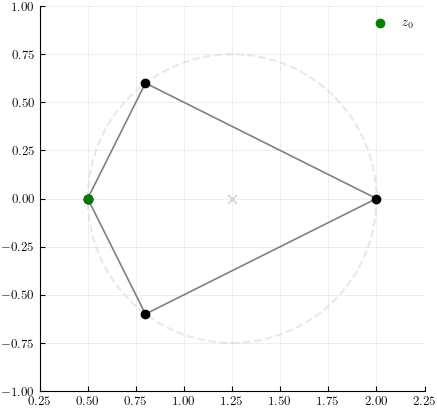

In [138]:
center = center_circle
radius = radius_circle + 0.25

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
add_circle(fig, ax, center_circle, radius_circle)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [139]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

In [140]:
z0 = complex(0, 2)
filename = "mobius_two_fixed_points_periodic_orbit_imaginary_axis.pdf"

In [141]:
iterations = 4
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

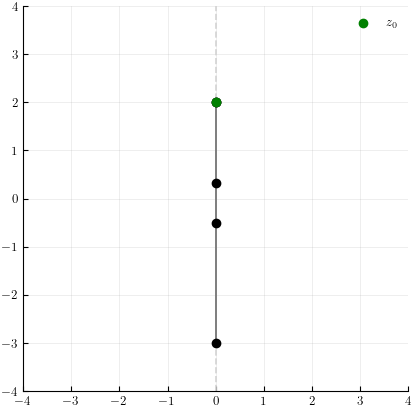

In [144]:
center = 0
radius = max(abs(orbit.imag)) + 1

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
ax.axvline(0, color="lightgray", linestyle="--", zorder=1)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [145]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

### $R(z) = e^{2i}z$

In [23]:
theta = 2  # 2*np.pi/np.pi, es decir, la vuelta completa partida en pi trozos
k = 1 * np.exp(theta * 1j)

R = RationalMap.from_latex(rf"{k}z", imag_const="j")
print(R)

filename = "mobius_two_fixed_points_dense_orbit_10.pdf"

z0 = 1

z \left(- \frac{7496634952020485}{18014398509481984} + \frac{4095111552621091 i}{4503599627370496}\right)


In [24]:
iterations = 10
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

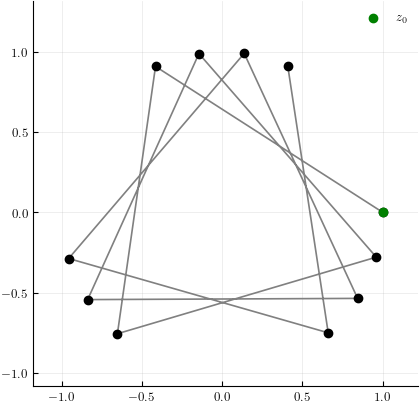

In [25]:
center = complex(
    (max(orbit.real) + min(orbit.real)) / 2,
    (max(orbit.imag) + min(orbit.imag)) / 2,
)
radius = 1.2

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [26]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

In [27]:
filename = "mobius_two_fixed_points_dense_orbit_100.pdf"

In [28]:
iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=iterations)

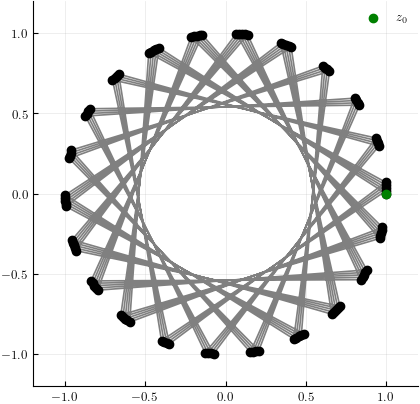

In [29]:
center = complex(
    (max(orbit.real) + min(orbit.real)) / 2,
    (max(orbit.imag) + min(orbit.imag)) / 2,
)
radius = 1.2

xmin = center.real - radius
xmax = center.real + radius
ymin = center.imag - radius
ymax = center.imag + radius

fig, ax = dplot.plot_orbit(orbit)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

In [30]:
if save_figures and filename is not None:
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / filename, dpi=dpi, bbox_inches="tight", pad_inches=0
    )
plt.close(fig)

## Section 2: Polinomios de grado dos
### $P(z) = z^2$

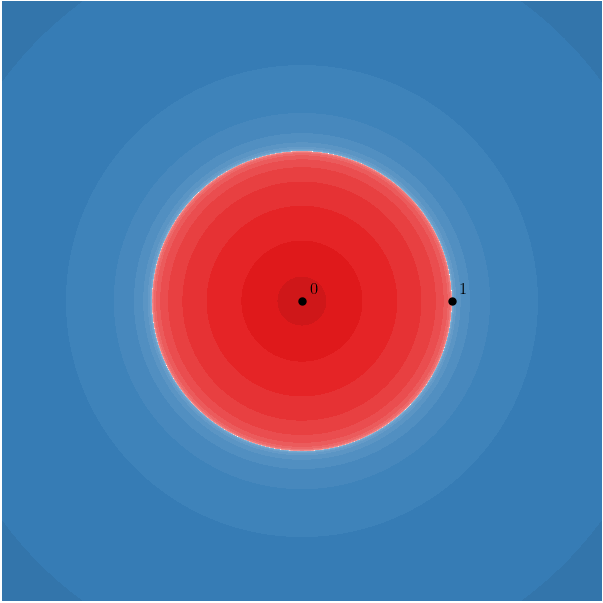

In [32]:
R = RationalMap.from_latex(r"z^2")
mesh, extent = make_mesh()
attractors = np.array([0, np.inf], dtype=np.complex128)
times, points = dcalc.calculate_convergence_times(
    mesh,
    R=R,
    attractors=attractors,
    max_iterations=max_iterations,
    tolerance=tolerance,
)
plot_basins(
    times,
    points,
    attractors,
    extent,
    "z_squared_fatou_basins_and_times.pdf",
    labels=[(0, "$0$"), (1, "$1$")],
)

### La familia cuadrática $z^2+c$
#### $P_{-1}(z)=z^2-1$

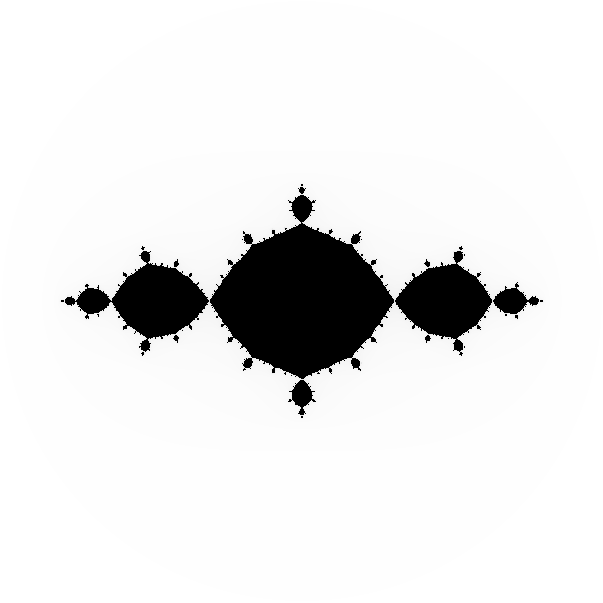

In [33]:
R = RationalMap.from_latex(r"z^2 - 1")
mesh, extent = make_mesh()
iterations = 256
times = dcalc.calculate_divergence_times(
    mesh,
    R=R,
    max_iterations=iterations,
    escape_radius=2.0,
)
plot_escape(times, extent, iterations, "z_squared_minus_one_escape_times.pdf")

#### Alternativas (Descartadas)

El punto $0$ representa el ciclo atractor $0\leftrightarrow-1$: entrar cerca de uno de sus puntos permite etiquetar la cuenca del ciclo. Las fronteras se extraen de las etiquetas de convergencia, no de todos los niveles de tiempo.

In [ ]:
attractors = np.array([0, np.inf], dtype=np.complex128)
times, points = dcalc.calculate_convergence_times(
    mesh,
    R=R,
    attractors=attractors,
    max_iterations=max_iterations,
    tolerance=tolerance,
)
fig, ax = new_axes(extent)
dplot.plot_convergence_times(
    times,
    points,
    attractors=attractors,
    max_iterations=max_iterations,
    ax=ax,
    extent=extent,
    interpolation="nearest",
)
add_point(ax, 0, "$0$", marker="x")
add_point(ax, -1, "$-1$", marker="x")
add_point(ax, (1 + np.sqrt(5)) / 2, r"$\frac{1+\sqrt{5}}{2}$")
add_point(ax, (1 - np.sqrt(5)) / 2, r"$\frac{1-\sqrt{5}}{2}$")
finish_figure(fig, ax, "z_squared_minus_one_fatou_basins_and_times.pdf")
plot_boundary(points, extent, "z_squared_minus_one_julia_set.pdf")

In [ ]:
mesh, extent = make_mesh(y_radius=1.0)
times, points = dcalc.calculate_convergence_times(
    mesh,
    R=R,
    attractors=attractors,
    max_iterations=max_iterations,
    tolerance=tolerance,
)
plot_boundary(points, extent, "z_squared_minus_one_julia_set-thin.pdf")

#### $P_1(z)=z^2+1$

In [ ]:
R = RationalMap.from_latex(r"z^2 + 1")
mesh, extent = make_mesh()
iterations = 256
times = dcalc.calculate_divergence_times(
    mesh,
    R=R,
    max_iterations=iterations,
    escape_radius=2.0,
)
# Preview only, as in the original notebook (no PDF export).
plot_escape(times, extent, iterations)

#### $P_c(z)=z^2+c$

Los coeficientes de `RationalMap` se dan en orden ascendente: `[c, 0, 1]` representa $c+z^2$. Se conservan los cinco valores originales; `cTest` coincidía con `c1`, por lo que ya no se calcula por duplicado.

In [ ]:
parameters = {
    "c1": -0.836 - 0.232j,
    "c2": 0.285 + 0.01j,
    "c3": -0.4 + 0.6j,
    "c4": -0.54 - 0.54j,
    "c5": -0.12256117 + 0.74486177j,
}
mesh, extent = make_mesh()
iterations = 128
for name, c in parameters.items():
    R = RationalMap([c, 0, 1], [1])
    times = dcalc.calculate_divergence_times(
        mesh,
        R=R,
        max_iterations=iterations,
        escape_radius=2.0,
    )
    print(f"{name}: c = {c}")
    plot_escape(
        times, extent, iterations, f"z_squared_plus_{name}_escape_times.pdf"
    )

#### Mandelbrot Set

Aquí cada píxel es un parámetro $c$ y se itera $z_0=0$. `calculate_divergence_times` usa un único mapa fijo para todos los píxeles, así que no sirve directamente para este cálculo. El siguiente helper local utiliza la malla del paquete y NumPy, sin los antiguos módulos ni Numba. Se conserva el radio de escape original.

In [ ]:
def mandelbrot_escape_times(parameters, *, max_iterations, escape_radius):
    z = np.zeros(parameters.shape, dtype=np.complex128)
    times = np.zeros(parameters.shape, dtype=np.int64)
    active = np.ones(parameters.shape, dtype=bool)
    for _ in range(max_iterations):
        if not active.any():
            break
        z[active] = z[active] ** 2 + parameters[active]
        times[active] += 1
        active &= np.isfinite(z) & (np.abs(z) < escape_radius)
    return times

In [ ]:
center = -0.75 + 0j
radius = 1.4
mesh, extent = make_mesh(center=center, radius=radius)
escape_radius = max(2 * (radius + abs(center)), 2.0)
iterations = 100
times = mandelbrot_escape_times(
    mesh,
    max_iterations=iterations,
    escape_radius=escape_radius,
)
plot_escape(times, extent, iterations, "mandelbrot_set.pdf", cmap="Grays")

In [ ]:
iterations = 256
times = mandelbrot_escape_times(
    mesh,
    max_iterations=iterations,
    escape_radius=escape_radius,
)
# Preserve the original 1/8 cutoff, not an exact membership test.
# This replaces the old helper that accidentally depended on global dimensions.
binary_times = (times >= iterations * 0.125).astype(np.int64)
plot_escape(binary_times, extent, 1, "mandelbrot_set-binary.pdf")

## Section 3: El Método de Newton

Para $P(z)=z^n-1$, el mapa de Newton es
$$N_P(z)=\frac{(n-1)z^n+1}{nz^{n-1}}.$$
Se usa esta forma racional reducida para tratar correctamente el polo $z=0$. Los atractores son las raíces $n$-ésimas de la unidad. Se generan los ejemplos originales para $n=2,3,4,5$. El nuevo sombreado sustituye al antiguo `shading_power`.

Se conserva `z_forth_...` (la errata original) para no romper las referencias LaTeX.

In [ ]:
newton_examples = [
    (2, 4.0, "z_squared_minus_one_newton_fatou_basins_and_times.pdf"),
    (3, 2.0, "z_cubed_minus_one_newton_fatou_basins_and_times.pdf"),
    (4, 4.0, "z_forth_minus_one_newton_fatou_basins_and_times.pdf"),
    (5, 4.0, "z_fifth_minus_one_newton_fatou_basins_and_times.pdf"),
]
for degree, radius, filename in newton_examples:
    numerator = np.zeros(degree + 1)
    numerator[0], numerator[-1] = 1, degree - 1
    denominator = np.zeros(degree)
    denominator[-1] = degree
    R = RationalMap(numerator, denominator)
    attractors = np.exp(2j * np.pi * np.arange(degree) / degree)
    mesh, extent = make_mesh(radius=radius)
    times, points = dcalc.calculate_convergence_times(
        mesh,
        R=R,
        attractors=attractors,
        max_iterations=max_iterations,
        tolerance=tolerance,
    )
    fig, ax = new_axes(extent)
    dplot.plot_convergence_times(
        times,
        points,
        attractors=attractors,
        max_iterations=max_iterations,
        ax=ax,
        extent=extent,
        interpolation="nearest",
    )
    if degree == 2:
        add_point(ax, 1, "$1$")
        add_point(ax, -1, "$-1$")
    elif degree == 3:
        add_point(ax, 1, "$1$", offset=(18, 6))
        add_point(
            ax,
            attractors[1],
            r"$-\frac{1}{2}+i\frac{\sqrt{3}}{2}$",
            offset=(-12, 36),
        )
        add_point(
            ax,
            attractors[2],
            r"$-\frac{1}{2}-i\frac{\sqrt{3}}{2}$",
            offset=(-12, -12),
        )
    elif degree == 4:
        for point, label in [
            (1, "$1$"),
            (1j, "$i$"),
            (-1, "$-1$"),
            (-1j, "$-i$"),
        ]:
            add_point(ax, point, label)
    print(f"Newton: P(z) = z^{degree} - 1")
    finish_figure(fig, ax, filename)